# Models

In [ ]:
# Installs (Minimal für Google GenAI, OpenAI SDK, LiteLLM & Model Garden)
############################################

# 1. Benötigte Pakete für Models installieren (ohne ADK)
%pip install --upgrade --quiet google-genai google-cloud-aiplatform openai litellm

# 2. Versionen kurz prüfen
%pip show google-genai google-cloud-aiplatform openai litellm

Note: you may need to restart the kernel to use updated packages.
Name: google-genai
Version: 2.33.0
Summary: GenAI Python SDK
Home-page: https://github.com/googleapis/python-genai
Author: 
Author-email: Google LLC <googleapis-packages@google.com>
License: 
Location: /opt/anaconda3/lib/python3.12/site-packages
Requires: anyio, distro, google-auth, httpx, pydantic, requests, sniffio, tenacity, typing-extensions, websockets
Required-by: google-adk, google-cloud-aiplatform
---
Name: google-cloud-aiplatform
Version: 2.6.0
Summary: Vertex AI API client library
Home-page: https://github.com/googleapis/python-aiplatform
Author: Google LLC
Author-email: googleapis-packages@google.com
License: Apache 2.0
Location: /opt/anaconda3/lib/python3.12/site-packages
Requires: certifi, docstring_parser, google-api-core, google-auth, google-cloud-bigquery, google-cloud-resource-manager, google-cloud-storage, google-genai, packaging, proto-plus, protobuf, pydantic, typing_extensions
Required-by: 
---
Name:

In [ ]:
# Imports (Minimal für Models)
############################################

import os
import warnings
warnings.filterwarnings('ignore')

# 1. Google Cloud Auth & Vertex AI
import google.auth
import google.auth.transport.requests
import vertexai
from vertexai import model_garden

# 2. Google GenAI SDK
from google import genai
from google.genai import types

# 3. OpenAI SDK (für Vertex AI OpenAI-kompatiblen Endpunkt)
from openai import OpenAI

# 4. LiteLLM
import litellm

print("✅ Alle Imports erfolgreich geladen!")


✅ Alle Imports erfolgreich geladen!


In [3]:
# Environmental Variables & GCP Setup
############################################

PROJECT_ID = "deltorobarba"
LOCATION = "us-central1"

# These tell the underlying google-genai client and SDK to use Vertex AI
os.environ["GOOGLE_GENAI_USE_VERTEXAI"] = "1"
os.environ["GOOGLE_CLOUD_PROJECT"] = PROJECT_ID
os.environ["GOOGLE_CLOUD_LOCATION"] = LOCATION

# Required by LiteLLM for Vertex AI partner models
os.environ["VERTEXAI_PROJECT"] = PROJECT_ID
os.environ["VERTEXAI_LOCATION"] = LOCATION

# Initialize Vertex AI SDK & Client via Application Default Credentials (ADC)
vertexai.init(project=PROJECT_ID, location=LOCATION)
client = vertexai.Client(project=PROJECT_ID, location=LOCATION)

print("✅ Erfolgreich über Application Default Credentials (ADC) verbunden.")

✅ Erfolgreich über Application Default Credentials (ADC) verbunden.


In [10]:
# Models on Google Cloud (Model Garden)
############################################

# ⚠️ Accept User Agreements per Model!

# Closed Models
geminipro   = "google/gemini-4-argon"
geminiflash = "google/gemini-3.8-flash"
grok        = "xai/grok-4.1-fast-reasoning"             # ✅ https://docs.cloud.google.com/vertex-ai/generative-ai/docs/partner-models/grok/grok-4-1-fast
claude      = "anthropic/claude-opus-4-7"

# Open Models (kimi, qwen, minimax not supported anymore)
gemma       = "google/gemma-4-26b-a4b-it-maas"          # ✅ https://docs.cloud.google.com/vertex-ai/generative-ai/docs/maas/google/gemma-4-26b-a4b-it
deepseek    = "deepseek-ai/deepseek-v4.1-flash-maas"    # ✅ https://docs.cloud.google.com/vertex-ai/generative-ai/docs/maas/deepseek/deepseek-v32
glm         = "zai-org/glm-5.2-maas"                    # ✅ https://docs.cloud.google.com/gemini-enterprise-agent-platform/models/maas/zaiorg/glm-52

In [6]:
# @title Google SDK (Fast Track)

from google import genai

client = genai.Client(vertexai=True, project="deltorobarba", location="global")

response = client.models.generate_content(
    model=gemma,
    contents="Hi, welche Fähigkeiten hast du? Bitte antworte kurz.",
)
print(response.text)

Ich bin Gemma 4, ein Large Language Model von Google DeepMind. Meine Fähigkeiten umfassen:

*   **Textverarbeitung:** Verstehen und Generieren von Texten in verschiedenen Sprachen und Stilen.
*   **Bildverarbeitung:** Analysieren und Interpretieren von Bildern.
*   **Audioverarbeitung:** Verarbeiten von Audioeingaben (verfügbar in den 2B- und 4B-Modellen meiner Familie).
*   **Wissensbasierte Aufgaben:** Beantworten von Fragen, Zusammenfassen, logisches Denken und Programmieren.

Ich generiere ausschließlich Text als Antwort und kann keine Bilder erstellen.


In [ ]:
# @title Google SDK (Full Track)

# https://github.com/se02035/local-llm-proxy it helps to spin up a litellm proxy with local ollama. also supports a public endpoint using ngrok

# Locations: https://docs.cloud.google.com/vertex-ai/generative-ai/docs/learn/locations
# Google Models: https://docs.cloud.google.com/vertex-ai/generative-ai/docs/models
# Versions: https://docs.cloud.google.com/vertex-ai/generative-ai/docs/learn/model-versions

# client = genai.Client(http_options=HttpOptions(api_version="v1")) --> only for Google models directly
# https://github.com/GoogleCloudPlatform/generative-ai/blob/main/sdk/intro_genai_sdk.ipynb
# https://docs.cloud.google.com/vertex-ai/generative-ai/docs/open-models/use-maas

from google import genai
from google.genai.types import GenerateContentConfig
from google.genai import types

PROJECT_ID="deltorobarba"
LOCATION = "global"
client = genai.Client(vertexai=True, project=PROJECT_ID, location=LOCATION)

system_instruction = """You are a helpful machine learning advisor and answer briefly."""
prompt = """Hi, which LLM are you? What is your name and what are your capabilities? Please answer briefly."""

generate_content_config = types.GenerateContentConfig(
    temperature=0.4,
    top_p=0.95,
    top_k=20,
    candidate_count=1,
    seed=5,
    max_output_tokens=120,
    stop_sequences=["STOP!"],
    presence_penalty=0.0,
    frequency_penalty=0.0,
    system_instruction=system_instruction,)

response = client.models.generate_content(
    model=geminipro,                       # <--- ⚠️ Define model here
    contents=prompt,
    config=generate_content_config,
)
print("✅ Success")
print(response.text)

✅ Success
Hello! I am **Gemini 4 Argon**, a large language model built by Google. 

As your machine learning advisor, my capabilities include:
* **Code Generation & Debugging:** Writing and optimizing ML code in Python, PyTorch, TensorFlow, and scikit-learn.
* **Architecture & Algorithm Selection:** Recommending the right models (from classical ML to deep learning) for your specific data and goals.
* **Data & MLOps Advice:** Assisting with data preprocessing, feature engineering, hyperparameter tuning, and model deployment strategies.
* **Concept Explanation


In [ ]:
# @title OpenAI SDK for LLMs on Google Cloud
#################################################

from openai import OpenAI

PROJECT  = "deltorobarba"
LOCATION = "global"

# Get access token from Application Default Credentials (run `gcloud auth application-default login` once beforehand)
"""
Kein OAuth2-Token-Management: Beim OpenAI SDK muss man manuell per google.auth.default() ein Google-Token anfordern und 
per credentials.refresh() erneuern (Token verfällt nach 60 Minuten!). Das Google SDK übernimmt die Authentifizierung über 
die lokalen Application Default Credentials (ADC) vollautomatisch im Hintergrund.
"""
credentials, _ = google.auth.default(
    scopes=["https://www.googleapis.com/auth/cloud-platform"]
)
credentials.refresh(google.auth.transport.requests.Request())

# Point OpenAI SDK at Vertex's OpenAI-compatible endpoint
client = OpenAI(
    base_url=f"https://aiplatform.googleapis.com/v1/projects/{PROJECT}/locations/{LOCATION}/endpoints/openapi",
    api_key=credentials.token,
)

# Call selected model like any OpenAI model
response = client.chat.completions.create(
    model=deepseek,
    messages=[{"role": "user", "content": "Hi, which LLM are you and which capabilities do you have? Answer me in Chinese."}],
    temperature=0.2,
)

print("✅ Success")
print(response.choices[0].message.content)

✅ Success
你好！我是 **DeepSeek**，由深度求索公司创造的AI助手。😊

以下是我的一些主要能力和特点：

**基本信息：**
- 知识截止日期：2026年2月
- 支持中文和多种语言
- 完全免费使用

**核心能力：**
1. **文本对话**：可以回答问题、写作、翻译、编程、分析等
2. **文件处理**：支持上传图像、txt、pdf、ppt、word、excel等文件，并从中读取文字信息
3. **长文本处理**：上下文长度达1M，可以一次性处理像《三体》三部曲这样体量的书籍
4. **联网搜索**：支持联网搜索功能（需要在Web/App端手动开启）
5. **语音输入**：App端支持语音输入
6. **阅读链接**：可以阅读网页链接内容

**注意事项：**
- 我支持图片输入，可以识别和分析图片中的可见信息，比如物体、场景、文字等
- 联网搜索需要用户手动开启

有什么我可以帮你的吗？无论是学习、工作还是生活问题，都可以问我！🌟


In [11]:
# @title OpenAI SDK for LLMs on Google Cloud
#################################################

from openai import OpenAI

PROJECT  = "deltorobarba"
LOCATION = "global"

# Get access token from Application Default Credentials (run `gcloud auth application-default login` once beforehand)
"""
Kein OAuth2-Token-Management: Beim OpenAI SDK muss man manuell per google.auth.default() ein Google-Token anfordern und 
per credentials.refresh() erneuern (Token verfällt nach 60 Minuten!). Das Google SDK übernimmt die Authentifizierung über 
die lokalen Application Default Credentials (ADC) vollautomatisch im Hintergrund.
"""
credentials, _ = google.auth.default(
    scopes=["https://www.googleapis.com/auth/cloud-platform"]
)
credentials.refresh(google.auth.transport.requests.Request())

# Point OpenAI SDK at Vertex's OpenAI-compatible endpoint
client = OpenAI(
    base_url=f"https://aiplatform.googleapis.com/v1/projects/{PROJECT}/locations/{LOCATION}/endpoints/openapi",
    api_key=credentials.token,
)

# Call selected model like any OpenAI model
response = client.chat.completions.create(
    model=glm,
    messages=[{"role": "user", "content": "Hi, which LLM are you and which capabilities do you have?"}],
    temperature=0.2,
)

print("✅ Success")
print(response.choices[0].message.content)

✅ Success
I'm GLM (General Language Model), a large language model developed by Z.ai. I'm designed to understand and generate human-like text through natural language processing.

My capabilities include answering questions, providing explanations, assisting with writing tasks, offering creative content suggestions, and engaging in conversational interactions across various topics. I can help with information analysis, summarization, and basic problem-solving.

I'm continuously learning to improve my responses while maintaining a helpful, respectful approach to user interactions. Is there something specific you'd like to know about my abilities or how I can assist you today?


In [24]:
# @title 📊 Model Benchmark: Speed (TTFT, Total Time, Tokens/sec) & LLM-as-a-Judge
################################################################################

import time
import pandas as pd
from google import genai

# 1. Client initialisieren
PROJECT_ID = "deltorobarba"
LOCATION = "global"
client = genai.Client(vertexai=True, project=PROJECT_ID, location=LOCATION)

# 2. Zu vergleichende Modelle & Test-Prompts definieren
models_to_test = [
    "gemini-3.8-flash",
    "deepseek-ai/deepseek-v4.1-flash-maas",  # oder Partner-MaaS Modelle wie deepseek-v4.1-flash-maas
]

test_prompts = {
    "Reasoning & Math": "Ein Zug fährt mit 120 km/h von A nach B (300 km). Ein zweiter Zug startet 30 Minuten später mit 150 km/h von B nach A. Wann und wo begegnen sie sich? Erkläre Schritt für Schritt.",
    "Code Generation": "Schreibe eine Python-Funktion mit Type Hints und Docstring, die einen Text einliest und die 3 häufigsten Wörter (ohne Stopwords) zurückgibt.",
    "Summarization": "Fasse die Kernunterschiede zwischen RAG (Retrieval-Augmented Generation) und Fine-Tuning in genau 3 prägnanten Bullet Points zusammen."
}

# 3. Benchmark-Funktion mit Streaming (misst TTFT + Generation Time)
def run_benchmark(models, prompts):
    results = []
    outputs = {}

    for prompt_name, prompt_text in prompts.items():
        print(f"\n🚀 Teste Kategorie: {prompt_name}...")
        outputs[prompt_name] = {}

        for model in models:
            model_short = model.split("/")[-1]
            try:
                start_time = time.perf_counter()
                ttft = None
                chunks = []
                last_chunk = None

                # Streaming für Time-To-First-Token (TTFT)
                stream = client.models.generate_content_stream(model=model, contents=prompt_text)
                for chunk in stream:
                    if ttft is None:
                        ttft = time.perf_counter() - start_time
                    if chunk.text:
                        chunks.append(chunk.text)
                    last_chunk = chunk

                total_time = time.perf_counter() - start_time
                full_text = "".join(chunks)
                outputs[prompt_name][model] = full_text

                # Token Usage aus Metadaten ermitteln
                usage = getattr(last_chunk, "usage_metadata", None)
                in_tokens = usage.prompt_token_count if usage else None
                out_tokens = usage.candidates_token_count if usage else None

                # Durchsatz (Tokens/s nach erstem Token)
                gen_time = total_time - (ttft or 0)
                tps = round(out_tokens / gen_time, 1) if (out_tokens and gen_time > 0) else "N/A"

                results.append({
                    "Kategorie": prompt_name,
                    "Modell": model_short,
                    "TTFT (s)": round(ttft, 3) if ttft else None,
                    "Gesamtzeit (s)": round(total_time, 3),
                    "Output Tokens": out_tokens,
                    "Tokens/Sek (TPS)": tps,
                })
                print(f"   ✅ {model_short}: TTFT={round(ttft, 2)}s, Gesamt={round(total_time, 2)}s, TPS={tps}")
            except Exception as e:
                print(f"   ❌ Fehler bei {model}: {e}")

    df = pd.DataFrame(results)
    return df, outputs

# Ausführen
df_results, collected_outputs = run_benchmark(models_to_test, test_prompts)
display(df_results)

# 4. Optional: LLM-as-a-Judge (Ein Richter-Modell bewertet beide Antworten blind)
def judge_pairwise(prompt, text_a, text_b, judge_model="gemini-3.8-flash"):
    judge_prompt = f"""
Du bist ein unparteiischer KI-Schiedsrichter. Bewerte die folgenden zwei Antworten auf die gegebene Frage.
Frage: {prompt}

--- Antwort A ---
{text_a}

--- Antwort B ---
{text_b}

Bewerte beide Antworten nach Genauigkeit, Struktur und Logik (Punkte 1-10).
Erkläre kurz deine Entscheidung und küre einen Gewinner (A, B oder Unentschieden).
"""
    response = client.models.generate_content(model=judge_model, contents=judge_prompt)
    print("\n⚖️ Richter-Urteil:")
    print(response.text)

# Beispiel: Richter für "Reasoning & Math" aufrufen
# judge_pairwise(test_prompts["Reasoning & Math"], collected_outputs["Reasoning & Math"][models_to_test[0]], collected_outputs["Reasoning & Math"][models_to_test[1]])



🚀 Teste Kategorie: Reasoning & Math...
   ✅ gemini-3.8-flash: TTFT=145.03s, Gesamt=153.02s, TPS=129.6
   ✅ deepseek-v4.1-flash-maas: TTFT=1.45s, Gesamt=15.21s, TPS=51.7

🚀 Teste Kategorie: Code Generation...
   ✅ gemini-3.8-flash: TTFT=212.72s, Gesamt=222.34s, TPS=157.1
   ✅ deepseek-v4.1-flash-maas: TTFT=0.88s, Gesamt=13.53s, TPS=91.1

🚀 Teste Kategorie: Summarization...
   ✅ gemini-3.8-flash: TTFT=237.1s, Gesamt=238.95s, TPS=102.1
   ✅ deepseek-v4.1-flash-maas: TTFT=2.34s, Gesamt=12.82s, TPS=12.0


,Kategorie,Modell,TTFT (s),Gesamtzeit (s),Output Tokens,Tokens/Sek (TPS)
0,Reasoning & Math,gemini-3.8-flash,145.030,153.022,1036,129.6
1,Reasoning & Math,deepseek-v4.1-flash-maas,1.450,15.211,712,51.7
2,Code Generation,gemini-3.8-flash,212.716,222.337,1511,157.1
3,Code Generation,deepseek-v4.1-flash-maas,0.877,13.526,1152,91.1
4,Summarization,gemini-3.8-flash,237.102,238.953,189,102.1
5,Summarization,deepseek-v4.1-flash-maas,2.343,12.818,126,12.0


📈 Benchmark-Auswertung: Gemini 3.8 Flash vs. DeepSeek V4.1 Flash MaaS

| Kategorie | Modell | TTFT (Reaktionszeit) | Gesamtzeit | Output Tokens | Durchsatz (TPS) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Reasoning & Math** | `gemini-3.8-flash`<br>`deepseek-v4.1-flash-maas` | 145.0 s<br>**1.45 s** ⚡ | 153.0 s<br>**15.2 s** ⚡ | **1.036**<br>712 | **129.6 TPS** 🚀<br>51.7 TPS |
| **Code Generation** | `gemini-3.8-flash`<br>`deepseek-v4.1-flash-maas` | 212.7 s<br>**0.88 s** ⚡ | 222.3 s<br>**13.5 s** ⚡ | **1.511**<br>1.152 | **157.1 TPS** 🚀<br>91.1 TPS |
| **Summarization** | `gemini-3.8-flash`<br>`deepseek-v4.1-flash-maas` | 237.1 s<br>**2.34 s** ⚡ | 239.0 s<br>**12.8 s** ⚡ | **189**<br>126 | **102.1 TPS** 🚀<br>12.0 TPS |

---

🔍 Kern-Erkenntnisse & Interpretation

**1. TTFT (Time-to-First-Token), Interaktivität & Latenz-Diskrepanz**
* **DeepSeek V4.1 Flash gewinnt bei der Reaktionszeit haushoch:** Mit **0.88 s bis 2.34 s** TTFT (0.88 s bei Code) beginnt das Streaming praktisch sofort, und die Antworten sind nach 12–15 Sekunden komplett fertig. Für synchrone Chatbots und kundennahe UIs ist das unschlagbar reaktiv.
* **Gemini 3.8 Flash hat eine extrem hohe Initial-Wartezeit (145–237 Sekunden, also rund 2,5–4 Minuten):**
  * *Warum ist das so?* Gemini 3.8 nutzt standardmäßig ein tiefes **Extended Reasoning / Deep Thinking**: Das Modell plant und durchdenkt die Lösung intern mit Denk-Tokens, bevor das erste für den Nutzer sichtbare Zeichen gestreamt wird. Hinzu kommt eine höhere Warteschlangen-Latenz (Queueing) auf dem globalen Vertex-AI-Preview-Endpunkt.

**2. Generierungs-Durchsatz & Rohgeschwindigkeit (Tokens per Second, TPS)**
* **Sobald Gemini 3.8 Flash einmal loslegt, ist die reine Inferenz extrem schnell:** Mit **130 bis 157 Tokens/Sekunde** generiert Gemini etwa 1,7- bis 2,5-mal so schnell wie DeepSeek (51–91 TPS).
* DeepSeek liefert einen soliden, gleichmäßigen Durchsatz, bricht aber bei sehr kurzen Aufgaben (Summarization: 12 TPS) im Ausgabestrom deutlich ein.

**3. Detailgrad & Token-Volumen**
* Gemini 3.8 Flash generiert durchgängig **30 % bis 50 % mehr Tokens**: Es formuliert deutlich ausführlichere Lösungen und Erklärungen, durchdachte Edge-Case-Absicherungen und detaillierte Code-Kommentare.

---

💡 Fazit & Empfehlung für die Praxis

* **Wann du `deepseek-v4.1-flash-maas` wählen solltest:**
  * **Client-Facing Chatbots, interaktive User Interfaces & Live-Chats:** Wenn ein Mensch vor dem Bildschirm sitzt und innerhalb von 1–2 Sekunden Text sehen muss (sofortiges Nutzer-Feedback, Gesamtzeit rund 13–15 s).
  * **Einfache Aufgaben / Quick Lookups:** Wo eine Antwort nach rund 13 Sekunden vollkommen ausreicht.

* **Wann du `gemini-3.8-flash` wählen solltest:**
  * **Asynchrone Agenten-Pipelines & Complex Reasoning ([agents.ipynb](agents.ipynb)):** In Hintergrund-Workflows, bei denen der Nutzer nicht sekündlich zuschaut, zahlen sich die Reasoning-Tiefe, die gründliche Analyse mit tieferer logischer Verknüpfung, die Anbindung an Google Search und Vertex AI Search und der hohe Durchsatz von bis zu 157 TPS maximal aus.

**⏱️ Latenz-Analyse: Perzentile (P50, P90, P95, P99)**

In produktiven Systemen und API-Benchmarks ist der klassische arithmetische Durchschnitt (*Mean*) oft trügerisch, da wenige extreme Ausreißer (z. B. durch Cold Starts oder API-Queueing) den Wert verzerren. Stattdessen nutzt man **Perzentile (Quantile)**, um die reale Latenzverteilung abzubilden:

```
Schnell ◄─────────────────────────────────────────────────────────────────► Langsam
[===================== P50 =====================][====== P90 ======][= P99 =]
                 50 % der Anfragen                     40 %             9 %     1 %
           (Der typische Normalfall)                (Verzögert)               (Spitzen)
```

### Die Kennzahlen im Überblick

| Metrik | Definition | Bedeutung in der Praxis |
| :--- | :--- | :--- |
| **P50 (Median)** | **50 %** aller Anfragen waren schneller als dieser Wert. | Der **echte Normalfall**, den die Mehrheit der Nutzer erlebt (robust gegen Ausreißer). |
| **P90** | **90 %** aller Anfragen waren schneller (nur 10 % langsamer). | Erwartbare Latenz bei **erhöhter Auslastung** oder leichter Netzwerkverzögerung. |
| **P95** | **95 %** aller Anfragen waren schneller. | Gängiger **Industrie-Standard für SLAs** (Service Level Agreements). |
| **P99 (*Tail Latency*)** | **99 %** aller Anfragen waren schneller (nur das langsamste 1 % lag darüber). | Der **Worst Case** (z. B. Modell-Cold-Start, Backend-Drosselung oder Re-Routing). |


[!IMPORTANT] **Warum das für Agenten (`agents.ipynb`) entscheidend ist:**

In parallelen Workflows (wie deinem Fan-Out mit `web_agent` und `doc_agent`, die an einem `JoinNode` zusammenlaufen) bestimmt **immer der langsamste Pfad** das Gesamttempo. Selbst wenn 9 von 10 Aufrufen schnell sind (P50), wird ein paralleler Workflow durch den P90- oder P99-Ausreißer ausgebremst.


🚀 Starte Perzentil-Benchmark für 'deepseek-ai/deepseek-v4.1-flash-maas' (10 Durchläufe)...
   Run 01/10: TTFT = 1.60s | Gesamtzeit = 2.53s
   Run 02/10: TTFT = 4.84s | Gesamtzeit = 6.13s
   Run 03/10: TTFT = 0.29s | Gesamtzeit = 0.96s
   Run 04/10: TTFT = 0.35s | Gesamtzeit = 1.75s
   Run 05/10: TTFT = 0.36s | Gesamtzeit = 1.70s
   Run 06/10: TTFT = 0.27s | Gesamtzeit = 1.73s
   Run 07/10: TTFT = 0.54s | Gesamtzeit = 2.20s
   Run 08/10: TTFT = 0.22s | Gesamtzeit = 1.29s
   Run 09/10: TTFT = 0.28s | Gesamtzeit = 1.71s
   Run 10/10: TTFT = 0.32s | Gesamtzeit = 1.96s

📊 Statistische Zusammenfassung:


,Metrik,TTFT (s),Gesamtzeit (s)
0,Min,0.219,0.956
1,P50 (Median),0.331,1.741
2,Mean (Ø),0.906,2.196
3,P90,1.926,2.889
4,P95,3.381,4.509
5,P99,4.544,5.804
6,Max,4.835,6.128


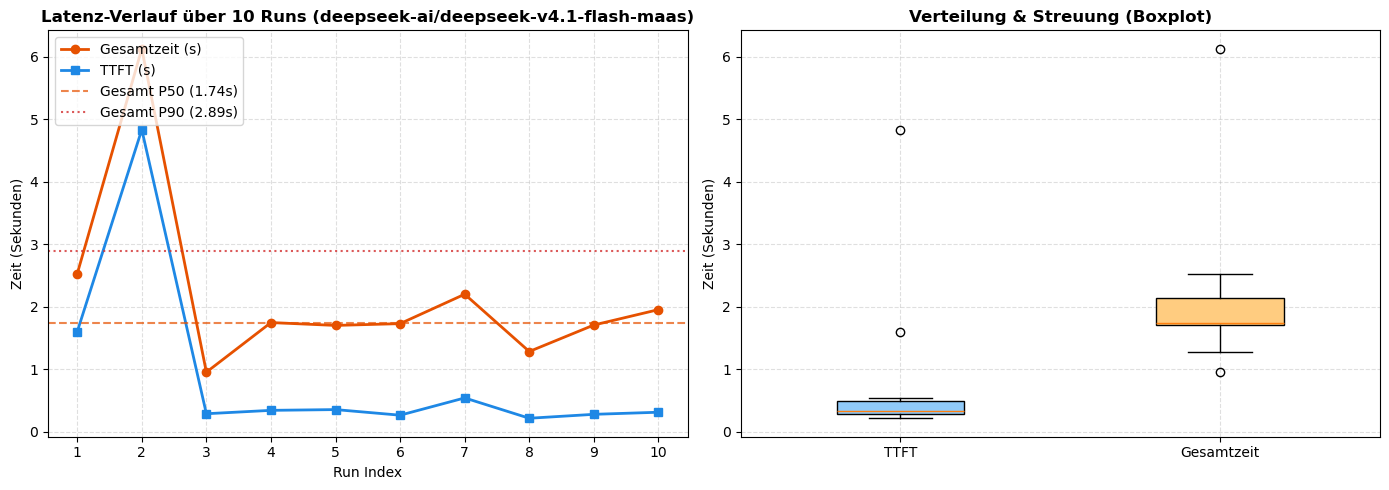

In [3]:
# @title ⏱️ Single-Model Latency Benchmark: P50, P90, P95, P99 & Distribution
#################################################################################

import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from google import genai

# 1. Konfiguration
PROJECT_ID = "deltorobarba"
LOCATION = "global"

# Wähle das zu testende Modell (z. B. "deepseek-ai/deepseek-v4.1-flash-maas" oder "gemini-3.8-flash")
MODEL_TO_TEST = "deepseek-ai/deepseek-v4.1-flash-maas"
PROMPT = "Erkläre kurz das Prinzip der Quantenverschränkung in genau 3 Sätzen."
NUM_RUNS = 10  # Anzahl der Test-Wiederholungen für statistische Signifikanz

# 2. Client initialisieren
client = genai.Client(vertexai=True, project=PROJECT_ID, location=LOCATION)

# 3. Mess-Schleife
print(f"🚀 Starte Perzentil-Benchmark für '{MODEL_TO_TEST}' ({NUM_RUNS} Durchläufe)...")
run_data = []

for i in range(1, NUM_RUNS + 1):
    start_time = time.perf_counter()
    ttft = None
    first_chunk = True
    full_text = []

    try:
        stream = client.models.generate_content_stream(model=MODEL_TO_TEST, contents=PROMPT)
        for chunk in stream:
            if first_chunk:
                ttft = time.perf_counter() - start_time
                first_chunk = False
            if chunk.text:
                full_text.append(chunk.text)

        total_time = time.perf_counter() - start_time
        run_data.append({
            "Run": i,
            "TTFT (s)": ttft if ttft is not None else total_time,
            "Gesamtzeit (s)": total_time,
        })
        print(f"   Run {i:02d}/{NUM_RUNS}: TTFT = {ttft:.2f}s | Gesamtzeit = {total_time:.2f}s")
    except Exception as e:
        print(f"   ❌ Fehler in Run {i}: {e}")

    # Kurze Pause zwischen Requests, um API-Burst-Limits zu vermeiden
    if i < NUM_RUNS:
        time.sleep(1.0)

# 4. Statistische Auswertung (P50, P90, P95, P99)
if not run_data:
    print("❌ Keine erfolgreichen Durchläufe zur Auswertung vorhanden.")
else:
    df_runs = pd.DataFrame(run_data)

    stats = {
        "Metrik": ["Min", "P50 (Median)", "Mean (Ø)", "P90", "P95", "P99", "Max"],
        "TTFT (s)": [
            df_runs["TTFT (s)"].min(),
            np.percentile(df_runs["TTFT (s)"], 50),
            df_runs["TTFT (s)"].mean(),
            np.percentile(df_runs["TTFT (s)"], 90),
            np.percentile(df_runs["TTFT (s)"], 95),
            np.percentile(df_runs["TTFT (s)"], 99),
            df_runs["TTFT (s)"].max(),
        ],
        "Gesamtzeit (s)": [
            df_runs["Gesamtzeit (s)"].min(),
            np.percentile(df_runs["Gesamtzeit (s)"], 50),
            df_runs["Gesamtzeit (s)"].mean(),
            np.percentile(df_runs["Gesamtzeit (s)"], 90),
            np.percentile(df_runs["Gesamtzeit (s)"], 95),
            np.percentile(df_runs["Gesamtzeit (s)"], 99),
            df_runs["Gesamtzeit (s)"].max(),
        ]
    }

    df_stats = pd.DataFrame(stats).round(3)

    print("\n📊 Statistische Zusammenfassung:")
    display(df_stats)

    # 5. Visualisierung der Latenzverteilung
    p50_total = np.percentile(df_runs["Gesamtzeit (s)"], 50)
    p90_total = np.percentile(df_runs["Gesamtzeit (s)"], 90)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Plot 1: Latenz-Verlauf über alle Runs hinweg mit P50/P90-Schwellen
    ax1.plot(df_runs["Run"], df_runs["Gesamtzeit (s)"], marker="o", color="#E65100", label="Gesamtzeit (s)", linewidth=2)
    ax1.plot(df_runs["Run"], df_runs["TTFT (s)"], marker="s", color="#1E88E5", label="TTFT (s)", linewidth=2)
    ax1.axhline(p50_total, color="#E65100", linestyle="--", alpha=0.7, label=f"Gesamt P50 ({p50_total:.2f}s)")
    ax1.axhline(p90_total, color="#D32F2F", linestyle=":", alpha=0.8, label=f"Gesamt P90 ({p90_total:.2f}s)")
    ax1.set_title(f"Latenz-Verlauf über {NUM_RUNS} Runs ({MODEL_TO_TEST})", fontsize=12, fontweight="bold")
    ax1.set_xlabel("Run Index", fontsize=10)
    ax1.set_ylabel("Zeit (Sekunden)", fontsize=10)
    ax1.set_xticks(df_runs["Run"])
    ax1.grid(True, linestyle="--", alpha=0.4)
    ax1.legend(loc="upper left")

    # Plot 2: Boxplot für TTFT und Gesamtzeit (abwärtskompatibel zu älteren Matplotlib-Versionen)
    boxplot_data = [df_runs["TTFT (s)"], df_runs["Gesamtzeit (s)"]]
    try:
        box = ax2.boxplot(boxplot_data, tick_labels=["TTFT", "Gesamtzeit"], patch_artist=True, widths=0.4)
    except TypeError:
        box = ax2.boxplot(boxplot_data, labels=["TTFT", "Gesamtzeit"], patch_artist=True, widths=0.4)

    colors = ["#90CAF9", "#FFCC80"]
    for patch, color in zip(box["boxes"], colors):
        patch.set_facecolor(color)
    ax2.set_title("Verteilung & Streuung (Boxplot)", fontsize=12, fontweight="bold")
    ax2.set_ylabel("Zeit (Sekunden)", fontsize=10)
    ax2.grid(True, linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()


**Bewertung der Testergebnisse: DeepSeek V4.1 Flash MaaS**

Detaillierte Analyse des Benchmark-Laufs über 10 Iterationen:

| Metrik | TTFT (Time-To-First-Token) | Gesamtzeit (3 Sätze) | Interpretation |
| :--- | :--- | :--- | :--- |
| **Min** | **0.22 s (219 ms)** | **0.96 s** | Bestmöglicher Durchsatz bei warmem Cache & freier Queue |
| **P50 (Median)** | **0.33 s (331 ms)** | **1.74 s** | **Typisches Nutzererlebnis:** Extrem schnell und responsiv |
| **Mean (Ø)** | 0.91 s | 2.20 s | Statistisch verzerrt durch die ersten beiden Ausreißer |
| **P90** | **1.93 s** | **2.89 s** | 90 % aller Anfragen sind in unter 2,9 Sekunden fertig |
| **P95 / Max** | **4.84 s** | **6.13 s** | Tail Latency Spike (Run 2: Provider-Queue / MaaS-Allokation) |

---

Die wichtigsten Erkenntnisse:

1. **Lehrbuchbeispiel für P50 vs. Mean (Durchschnitt):**
   * Im regulären Betrieb (**Runs 3 bis 10**) reagiert DeepSeek extrem schnell: Das erste Token streamt stabil in **0.22 s bis 0.36 s** (220–360 ms) los, und die Antwort ist nach rund **1.7 s** fertig.
   * Der arithmetische Mittelwert (**Mean TTFT = 0.91 s**) ist fast dreimal so hoch wie der Median (**0.33 s**), weil Run 2 ihn nach oben zieht. Wer nur den Durchschnitt betrachtet, bekommt ein völlig falsches Bild der tatsächlichen Alltags-Performance; der Median spiegelt sie wider.

2. **Verhalten bei Kaltstart & Tail-Spikes (P90 / P95):**
   * **Run 1 (1.60 s TTFT):** Typischer Handshake- und Routing-Overhead beim ersten Verbindungsaufbau.
   * **Run 2 (4.84 s TTFT):** Ein klassischer Infrastruktur-Ausreißer auf Vertex AI MaaS, z. B. durch dynamische Container-Zuweisung und -Skalierung (Autoscaling), Instanz-Zuweisung oder kurzzeitiges API-Queueing im GCP-Cluster.

3. **Praktische Empfehlung für Produktion & Agenten:**
   * **Für Chatbots, interaktive UIs & User-Facing Frontends:** Hervorragend geeignet. 8 von 10 Anfragen beginnen in rund 300 Millisekunden zu streamen; das fühlt sich für Anwender praktisch latenzfrei, flüssig und interaktiv an.
   * **Für Agenten-Pipelines ([agents.ipynb](agents.ipynb)):** Wenn ein Agent mehrere Modell-Aufrufe oder Schritte nacheinander ausführt (z. B. Tool-Calls oder Verzweigungen), steigt die Wahrscheinlichkeit, irgendwann einen P90/P95-Spike zu treffen. Wichtig: HTTP- bzw. Client-Timeouts in Agent-Knoten **nicht** auf den Median (1.7 s) oder auf 2–3 s setzen, sondern mindestens **7 bis 8 Sekunden** Puffer einplanen, damit Ausreißer wie in Run 2 nicht abgebrochen werden.

In [ ]:
# @title Model Evaluation
################################################################################

# https://docs.cloud.google.com/vertex-ai/generative-ai/docs/models/evaluation-overview
# https://github.com/GoogleCloudPlatform/generative-ai/blob/main/gemini/evaluation/quick_start_gen_ai_eval.ipynb

import os
import pandas as pd
import vertexai
from vertexai import Client
# Wichtig: RubricMetric aus vertexai._genai.types importieren, um Namespace-Kollisionen zu vermeiden:
from vertexai._genai.types import RubricMetric

# 1. Config & Vertex AI Evaluation Client
PROJECT_ID = "deltorobarba"
# Gemini 3.8 Flash & MaaS-Modelle liegen auf dem globalen Endpoint
LOCATION = "global"

vertexai.init(project=PROJECT_ID, location=LOCATION)
eval_client = Client(project=PROJECT_ID, location=LOCATION)

# ==============================================================================
# Model Evaluation (Multi-Model Comparison mit Rubrics)
# ==============================================================================

# ----- 2. Test-Prompts definieren -----
prompts_df = pd.DataFrame(
    {
        "prompt": [
            "Explain the difference between correlation and causation, and provide a real-world example where confusing the two could lead to poor decision-making.",
            "Write a Python function that finds the longest palindromic substring in a given string. Include comments explaining your approach and time complexity.",
            "A train leaves Station A at 9:00 AM traveling at 60 mph toward Station B. Another train leaves Station B at 10:00 AM traveling at 80 mph toward Station A. If the stations are 280 miles apart, at what time do the trains meet?",
            "Analyze the ethical implications of using AI in hiring decisions. Present arguments from multiple perspectives and discuss potential safeguards.",
            "Translate the following sentence to French, Spanish, and German, then explain any cultural nuances that might affect the translation: 'The early bird catches the worm, but the second mouse gets the cheese.'",
            "Create a short story (200 words) that includes these elements: a mysterious package, a lighthouse keeper, and a revelation that changes everything. The story should have a clear beginning, middle, and end.",
            "Compare and contrast the economic theories of Adam Smith and Karl Marx. How would each theorist likely view modern gig economy platforms like Uber?",
            "Debug this code and explain what's wrong: def fibonacci(n): if n <= 1: return n else: return fibonacci(n-1) + fibonacci(n-2) + fibonacci(n-3)",
            "You're a manager and an employee consistently delivers excellent work but is frequently late to meetings. Write a constructive feedback message addressing this issue while maintaining morale.",
            "Explain how transformer architecture works in machine learning to someone with basic programming knowledge but no ML background. Use an analogy to clarify the concept of attention mechanisms.",
        ]
    }
)

# ----- 3. Rubriken für Bewertung generieren -----
data_with_rubrics = eval_client.evals.generate_rubrics(
    src=prompts_df,
    rubric_group_name="general_quality_rubrics",
    predefined_spec_name=RubricMetric.GENERAL_QUALITY,
)

print("--- Running Inference & Evaluation for Models ---")

# --- Model 1: Gemini 3.8 Flash ---
gemini_dataset = eval_client.evals.run_inference(
    model="gemini-3.8-flash",
    src=data_with_rubrics,
)

# --- Model 2: DeepSeek MAAS Model ---
deepseek_dataset = eval_client.evals.run_inference(
    model="deepseek-ai/deepseek-v4.1-flash-maas",
    src=data_with_rubrics,
)

# --- 4. Comparison Evaluation ausführen ---
comparison_eval_result = eval_client.evals.evaluate(
    dataset=[gemini_dataset, deepseek_dataset],
    metrics=[
        RubricMetric.GENERAL_QUALITY(rubric_group_name="general_quality_rubrics")
    ],
)
comparison_eval_result.show()


In [ ]:
# @title Vertex AI - Deployment Recommendation
#################################################

from vertexai import model_garden

# Model Garden Identifier (Format: google/gemma4@gemma-4-26b-a4b-it oder google/gemma4@gemma-4-31b-it)
MODEL_ID = "google/gemma4@gemma-4-26b-a4b-it"

# Model Garden Objekt initialisieren
model = model_garden.OpenModel(MODEL_ID)

# Empfohlene/verifizierte Deployment-Optionen abrufen (concise=True für lesbare Übersicht)
deploy_options = model.list_deploy_options(concise=True)
print(deploy_options)

[Option 1: vLLM 256K context]
    serving_container_image_uri="us-docker.pkg.dev/vertex-ai/vertex-vision-model-garden-dockers/pytorch-vllm-serve:gemma4",
    machine_type="g4-standard-48",
    accelerator_type="NVIDIA_RTX_PRO_6000",
    accelerator_count=1,

[Option 2: vLLM 256K context spec decode]
    serving_container_image_uri="us-docker.pkg.dev/vertex-ai/vertex-vision-model-garden-dockers/pytorch-vllm-serve:20260505_0916_RC01",
    machine_type="g4-standard-48",
    accelerator_type="NVIDIA_RTX_PRO_6000",
    accelerator_count=1,

[Option 3: vLLM 256K context]
    serving_container_image_uri="us-docker.pkg.dev/vertex-ai/vertex-vision-model-garden-dockers/pytorch-vllm-serve:gemma4",
    machine_type="g4-standard-96",
    accelerator_type="NVIDIA_RTX_PRO_6000",
    accelerator_count=2,

[Option 4: vLLM 256K context]
    serving_container_image_uri="us-docker.pkg.dev/vertex-ai/vertex-vision-model-garden-dockers/pytorch-vllm-serve:gemma4",
    machine_type="a3-highgpu-1g",
    acceler

In [ ]:
# @title Vertex AI - Deployment Script ⚠️ BE CAREFUL (Deployment incurs costs!)

"""
Recommendation: NVIDIA RTX Pro 6000 (Blackwell) with VRAM	96 GB
We prefer NVIDIA L4 (Ada Lovelace) with VRAM 24 GB. Capacity: The L4 has 24 GB of GDDR6 memory.
The Problem: The Gemma 4 26B model in full precision (BF16) requires roughly 52 GB of VRAM just to load the weights. It will not fit on a single L4 in that state.
The Solution (Quantization): To run this on an L4, you must use 4-bit quantization (like AWQ or INT4). In 4-bit mode, the weights take up only ~15–18 GB, which fits comfortably on a single L4.
The Catch: You will likely need to reduce your context window significantly (e.g., from 256K down to 8K or 16K) to stay within the L4's 24GB limit.
"""


"""
import vertexai
from vertexai import model_garden

vertexai.init(project="lunar-352813", location="europe-west4")

model = model_garden.OpenModel("google/gemma4@gemma-4-26b-a4b-it")
endpoint = model.deploy(
  accept_eula=True,
  machine_type="g4-standard-48",
  accelerator_type="NVIDIA_RTX_PRO_6000",
  accelerator_count=1,
  serving_container_image_uri="us-docker.pkg.dev/vertex-ai/vertex-vision-model-garden-dockers/pytorch-vllm-serve:gemma4",
  endpoint_display_name="gemma-4-26b-a4b-it-mg-one-click-deploy",
  model_display_name="gemma-4-26b-a4b-it-1777568163447",
  use_dedicated_endpoint=True,
  reservation_affinity_type="NO_RESERVATION",
)
"""

import vertexai
from vertexai import model_garden

vertexai.init(project="lunar-352813", location="europe-west4")

model = model_garden.OpenModel("google/gemma4@gemma-4-31b-it")
endpoint = model.deploy(
  accept_eula=True,
  machine_type="g4-standard-48",
  accelerator_type="NVIDIA_RTX_PRO_6000",
  accelerator_count=1,
  serving_container_image_uri="us-docker.pkg.dev/vertex-ai/vertex-vision-model-garden-dockers/pytorch-vllm-serve:gemma4",
  endpoint_display_name="gemma-4-31b-it-mg-one-click-deploy",
  model_display_name="gemma-4-31b-it-1777570278133",
  use_dedicated_endpoint=True,
  reservation_affinity_type="NO_RESERVATION",
)